In [1]:
import json
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
ConfusionMatrixDisplay,
PrecisionRecallDisplay,
RocCurveDisplay,
accuracy_score,
average_precision_score,
classification_report,
confusion_matrix,
mean_absolute_error,
mean_squared_error,
precision_score,
r2_score,
recall_score,
roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold,train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT=Path.cwd().parent
DATA=PROJECT_ROOT/"all_datasets"
MODELS=PROJECT_ROOT/"models"
MODELS.mkdir(exist_ok=True)

In [2]:
def make_preprocess(num_cols,cat_cols):
    return ColumnTransformer([
        ("num",Pipeline([
            ("impute",SimpleImputer(strategy="median")),
            ("scale",StandardScaler()),
        ]),num_cols),
        ("cat",Pipeline([
            ("impute",SimpleImputer(strategy="most_frequent")),
            ("onehot",OneHotEncoder(handle_unknown="ignore")),
        ]),cat_cols),
    ])

## Part A - Regression: Ordinary least squares versus ridge

In [3]:
insurance=pd.read_csv(DATA/"medical_cost_personal_dataset.csv")
print(insurance.head())

X=insurance.drop(columns="charges")
y=insurance["charges"]
num_cols=["age","bmi","children"]
cat_cols=["sex","smoker","region"]

X_train,X_valid,y_train,y_valid=train_test_split(
    X,y,test_size=0.20,random_state=42
)

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [4]:
fitted={}
predictions= {}
for name, estimator in{
    "linear regression": LinearRegression(),
    "ridge":Ridge(alpha=10.0),
}.items():
    model=Pipeline([("preprocess",make_preprocess(num_cols,cat_cols)),("model",estimator)])
    model.fit(X_train,y_train)
    fitted[name]=model
    predictions[name]=model.predict(X_valid)
    pred=predictions[name]
    print(f"\n{name}")
    print("MAE:",round(mean_absolute_error(y_valid,pred),2))
    print("RMSE:",round(np.sqrt(mean_squared_error(y_valid,pred)),2))
    print("R2:",round(r2_score(y_valid,pred),3))


linear regression
MAE: 4173.34
RMSE: 5792.33
R2: 0.784

ridge
MAE: 4238.82
RMSE: 5821.59
R2: 0.782


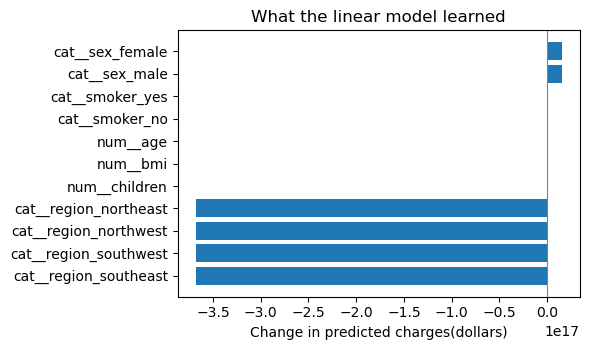

In [5]:
linear=fitted["linear regression"]
names=linear.named_steps["preprocess"].get_feature_names_out()
coefs=pd.Series(linear.named_steps["model"].coef_,index=names).sort_values()
plt.figure(figsize=(6,3.6))
plt.barh(coefs.index,coefs.values)
plt.axvline(0,color="grey",linewidth=0.8)
plt.xlabel("Change in predicted charges(dollars)")
plt.title("What the linear model learned")
plt.tight_layout()
plt.show()

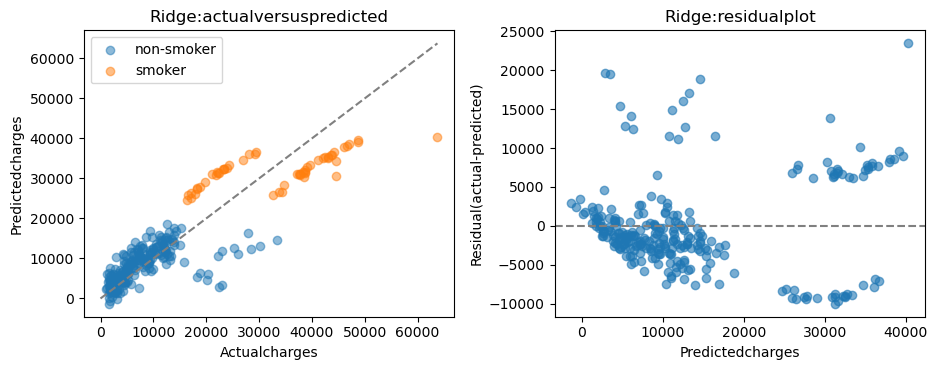

In [6]:
ridge_pred=predictions["ridge"]
residual=y_valid.to_numpy()-ridge_pred
is_smoker=(X_valid["smoker"]=="yes").to_numpy()
fig,axes=plt.subplots(1,2,figsize=(9.5, 3.8))

axes[0].scatter(y_valid[~is_smoker], ridge_pred[~is_smoker],alpha=0.5,label="non-smoker")
axes[0].scatter(y_valid[is_smoker],ridge_pred[is_smoker],alpha=0.5,label="smoker")
axes[0].plot([0,y_valid.max()],[0,y_valid.max()],linestyle="--",color="grey")
axes[0].set_xlabel("Actualcharges")
axes[0].set_ylabel("Predictedcharges")
axes[0].set_title("Ridge:actualversuspredicted")
axes[0].legend()
axes[1].scatter(ridge_pred,residual,alpha=0.6)
axes[1].axhline(0,linestyle="--",color="grey")
axes[1].set_xlabel("Predictedcharges")
axes[1].set_ylabel("Residual(actual-predicted)")
axes[1].set_title("Ridge:residualplot")
plt.tight_layout()
plt.show()

## Part B- Regression on a time series: validate in date order

In [7]:
bikes=pd.read_csv(DATA/"bike_sharing_dataset_day.csv")
bikes["dteday"]=pd.to_datetime(bikes["dteday"])
bikes=bikes.sort_values("dteday").reset_index(drop=True)

#cnt=casual+registered,sothosetwocolumnswouldleaktheanswer.
bike_cat=["season","yr","mnth","holiday","weekday","workingday","weathersit"]
bike_num=["temp","atemp","hum","windspeed"]
X_b=bikes[bike_cat+bike_num]
y_b=bikes["cnt"]

cut=int(len(bikes)*0.80)
print("train:",bikes["dteday"].iloc[0].date(),"to",bikes["dteday"].iloc[cut-1].date())
print("valid:",bikes["dteday"].iloc[cut].date(),"to",bikes["dteday"].iloc[-1].date())

train: 2011-01-01 to 2012-08-06
valid: 2012-08-07 to 2012-12-31


daily MAE: 1040.4 (mean daily demand in validation: 5897.8 )


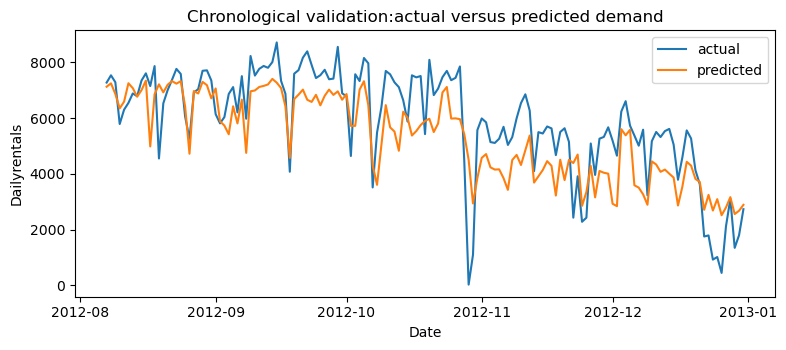

In [8]:
Xb_train,Xb_valid=X_b.iloc[:cut],X_b.iloc[cut:]
yb_train,yb_valid=y_b.iloc[:cut],y_b.iloc[cut:]
dates_valid= bikes["dteday"].iloc[cut:]

bike_model=Pipeline([
    ("preprocess",ColumnTransformer([
        ("cat",OneHotEncoder(handle_unknown="ignore"),bike_cat),
        ("num","passthrough",bike_num),
    ])),
    ("model", RandomForestRegressor(
        n_estimators=400,min_samples_leaf=2,random_state=42,n_jobs=-1
    )),
])
bike_model.fit(Xb_train,yb_train)
bike_pred=bike_model.predict(Xb_valid)
print("daily MAE:",round(mean_absolute_error(yb_valid,bike_pred),1),
      "(mean daily demand in validation:",round(yb_valid.mean(),1),")")

plt.figure(figsize=(8,3.6))
plt.plot(dates_valid,yb_valid.to_numpy(),label="actual")
plt.plot(dates_valid,bike_pred,label="predicted")
plt.xlabel("Date")
plt.ylabel("Dailyrentals")
plt.title("Chronological validation:actual versus predicted demand")
plt.legend()
plt.tight_layout()
plt.show()

hourly MAE: 56.5 (mean hourly demand in validation: 248.8 )


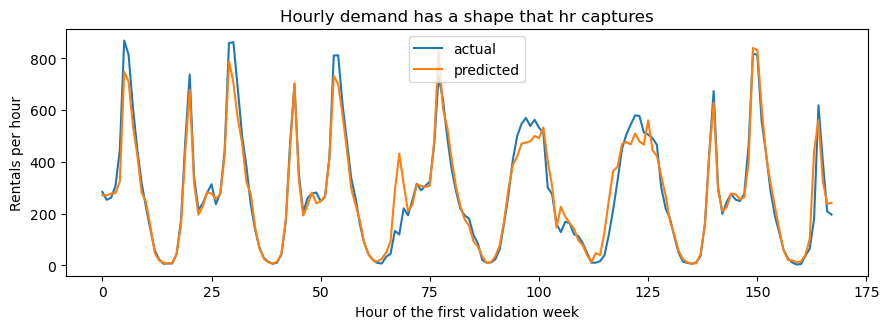

In [9]:
hourly=pd.read_csv(DATA/"bike_sharing_dataset_hour.csv")
hourly["dteday"]=pd.to_datetime(hourly["dteday"])
hourly=hourly.sort_values(["dteday","hr"]).reset_index(drop=True)
hour_cat=bike_cat+["hr"]
Xh=hourly[hour_cat+bike_num]
yh=hourly["cnt"]
cut_h=int(len(hourly)*0.80)
hour_model=Pipeline([
    ("preprocess",ColumnTransformer([
        ("cat",OneHotEncoder(handle_unknown="ignore"),hour_cat),
        ("num","passthrough",bike_num),
])),
    ("model", RandomForestRegressor(
        n_estimators=200,min_samples_leaf=2,random_state=42,n_jobs=-1
)),
])
hour_model.fit(Xh.iloc[:cut_h],yh.iloc[:cut_h])
hour_pred=hour_model.predict(Xh.iloc[cut_h:])
print("hourly MAE:",round(mean_absolute_error(yh.iloc[cut_h:],hour_pred),1),
      "(mean hourly demand in validation:", round(yh.iloc[cut_h:].mean(),1),")")

week=slice(0,24*7)
plt.figure(figsize=(9,3.4))
plt.plot(range(24*7),yh.iloc[cut_h:].to_numpy()[week],label="actual")
plt.plot(range(24*7),hour_pred[week],label="predicted")
plt.xlabel("Hour of the first validation week")
plt.ylabel("Rentals per hour")
plt.title("Hourly demand has a shape that hr captures")
plt.legend()
plt.tight_layout()
plt.show()

## Part C- Classification: baselines, probabilites, and the threshold

majority-classbaselineaccuracy: 0.614
logistic      accuracy=0.776roc_auc=0.842
random_forest accuracy=0.798roc_auc=0.834
threshold0.30:precision=0.64recall=0.81
threshold0.50:precision=0.72recall=0.67
threshold0.70:precision=0.90recall=0.50


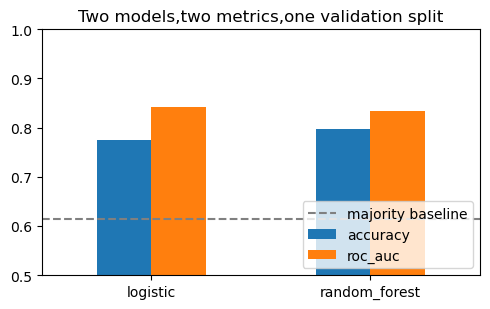

In [10]:
titanic=pd.read_csv(DATA/"titanic_dataset.csv")
features=["Pclass","Sex","Age","SibSp", "Parch","Fare","Embarked"]
t_num=["Age","SibSp","Parch","Fare"]
t_cat=["Pclass","Sex","Embarked"]
X_t=titanic[features]
y_t=titanic["Survived"]
Xt_train,Xt_valid,yt_train,yt_valid=train_test_split(
    X_t,y_t, test_size=0.25,random_state=42,stratify=y_t
)
print("majority-classbaselineaccuracy:",round(1-yt_valid.mean(),3))

scores={}
fitted_t={}
for name,estimator in{
    "logistic":LogisticRegression(max_iter=1000),
    "random_forest":RandomForestClassifier(n_estimators=300,min_samples_leaf=2,
                                           random_state=42),
}.items():
    pipe=Pipeline([("preprocess",make_preprocess(t_num,t_cat)),("model",estimator)])
    pipe.fit(Xt_train,yt_train)
    fitted_t[name]=pipe
    scores[name]={"accuracy":accuracy_score(yt_valid,pipe.predict(Xt_valid)),
                  "roc_auc":roc_auc_score(yt_valid,pipe.predict_proba(Xt_valid)[:,1])}
    print(f"{name:14s}accuracy={scores[name]['accuracy']:.3f}"
          f"roc_auc={scores[name]['roc_auc']:.3f}")

#Thesamelogisticmodel,threedecisionrules(thetableinthenotes).
prob_t=fitted_t["logistic"].predict_proba(Xt_valid)[:,1]
for threshold in[0.30,0.50,0.70]:
    pred_t=(prob_t>=threshold).astype(int)
    print(f"threshold{threshold:.2f}:precision={precision_score(yt_valid,pred_t):.2f}"
          f"recall={recall_score(yt_valid,pred_t):.2f}")

pd.DataFrame(scores).T.plot.bar(figsize=(5,3.2),ylim=(0.5,1.0),rot=0)
plt.axhline(1-yt_valid.mean(),linestyle="--",color="grey",label="majority baseline")
plt.title("Two models,two metrics,one validation split")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [11]:
cancer=pd.read_csv(DATA/"breast_cancer_dataset.csv")

X_c=cancer.drop(columns=["id","diagnosis","Unnamed:32"],errors="ignore")
y_c=(cancer["diagnosis"]=="M").astype(int)

Xc_train,Xc_valid,yc_train,yc_valid=train_test_split(
    X_c,y_c, test_size=0.25,random_state=42,stratify=y_c
)
cancer_model=Pipeline([
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])
cancer_model.fit(Xc_train,yc_train)
prob=cancer_model.predict_proba(Xc_valid)[:,1]

plt.figure(figsize=(6,3.4))
plt.hist(prob[yc_valid==0],bins=25,alpha=0.6,label="benign(actual)")
plt.hist(prob[yc_valid==1],bins=25,alpha=0.6,label="malignant(actual)")
plt.axvline(0.50,color="black",linestyle="--",label="threshold 0.50")
plt.axvline(0.30,color="red",linestyle=":",label="threshold 0.30")
plt.xlabel("Predicted probability of malignant")
plt.ylabel("Tumours")
plt.title("A threshold is a vertical line through this picture")
plt.legend()
plt.tight_layout()
plt.show()

C:\Users\ptivi\UTP\UTP\Anaconda\Lib\site-packages\sklearn\utils\extmath.py:1047: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
C:\Users\ptivi\UTP\UTP\Anaconda\Lib\site-packages\sklearn\utils\extmath.py:1052: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
C:\Users\ptivi\UTP\UTP\Anaconda\Lib\site-packages\sklearn\utils\extmath.py:1072: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


ValueError: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [12]:
for threshold in[0.50,0.30]:
    pred=(prob>=threshold).astype(int)
    print(f"\nthreshold={threshold:.2f}")
    print(confusion_matrix(yc_valid,pred))
    print(classification_report(yc_valid,pred,digits=3))
    ConfusionMatrixDisplay.from_predictions(yc_valid,pred,display_labels=["benign","malignant"])
    plt.title(f"Confusionmatrixatthreshold{threshold:.2f}")
    plt.tight_layout()
    plt.show()
    
thresholds=np.linspace(0.05,0.95,19)
precisions=[precision_score(yc_valid,(prob>=t).astype(int),zero_division=0)
            for t in thresholds]
recalls=[recall_score(yc_valid,(prob>=t).astype(int))fortinthresholds]

plt.figure(figsize=(6,3.4))
plt.plot(thresholds,precisions,marker="o", label="precision")
plt.plot(thresholds,recalls,marker="o",label="recall")
plt.xlabel("Decisionthreshold")
plt.ylabel("Score")
plt.title("Thethresholdtradesrecallforprecision")
plt.legend()
plt.tight_layout()
plt.show()

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1621521450.py, line 14)

In [1]:
print("ROCAUC:",round(roc_auc_score(yc_valid,prob),3))
print("PRAUC:",round(average_precision_score(yc_valid,prob),3))
fig,axes=plt.subplots(1,2,figsize=(9,3.6))
RocCurveDisplay.from_predictions(yc_valid, prob,ax=axes[0])
axes[0].set_title("ROCcurve")
PrecisionRecallDisplay.from_predictions(yc_valid,prob,ax=axes[1])
axes[1].set_title("Precision-recallcurve")
plt.tight_layout()
plt.show()

NameError: name 'roc_auc_score' is not defined

## Part D - Tune with cross-validation, then test once

In [2]:
X_train,X_test,y_train,y_test=train_test_split(
    X_t,y_t, test_size=0.25,random_state=42,stratify=y_t
)
search=GridSearchCV(
    Pipeline([("preprocess",make_preprocess(t_num,t_cat)),
              ("model",LogisticRegression(max_iter=2000))]),
    param_grid={
        "model__C":[0.01,0.1,1.0,10.0,100.0],
        "model__class_weight":[None,"balanced"],
    },
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42),
    n_jobs=-1,
)
search.fit(X_train,y_train)
cv_table=pd.DataFrame(search.cv_results_)
plt.figure(figsize=(5.5,3.4))
for weight,group in cv_table.groupby(cv_table["param_model__class_weight"].astype(str)):
    plt.errorbar(group["param_model__C"].astype(float),group["mean_test_score"],
                 yerr=group["std_test_score"],marker="o",capsize=3,label=f"class_weight={weight}")
plt.xscale("log")
plt.xlabel("C (weakerregularizationtotheright)")
plt.ylabel("Cross-validatedROCAUC")
plt.title("Whatthegridsearchsaw")
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'train_test_split' is not defined

In [6]:
test_prob=search.predict_proba(X_test)[:,1]
test_auc=roc_auc_score(y_test,test_prob)
print("best parameters:",search.best_params_)
print("cross-validated ROC AUC:",round(search.best_score_,3))
print("finaltest ROC AUC:",round(test_auc, 3))

NameError: name 'search' is not defined

In [4]:
final_model= search.best_estimator_
model_path=MODELS/"titanic_survival.joblib"
joblib.dump(final_model,model_path)
card={
    "task":"predictTitanicsurvival(1=survived)",
    "features":features,
    "model":"logisticregressionpipeline",
    "best_parameters":search.best_params_,
    "training_rows":int(len(X_train)),
    "final_test_roc_auc":round(float(test_auc),3),
    "decision_threshold":0.5,
    "scikit_learn_version":sklearn.__version__,
}
(MODELS/"titanic_survival_card.json").write_text(json.dumps(card,indent=2))
size_kb=model_path.stat().st_size/1024
print(f"saved:{model_path.name}({size_kb:.1f}KB)andtitanic_survival_card.json")

NameError: name 'search' is not defined

In [5]:
loaded = joblib.load(model_path)
new_passengers = pd.DataFrame([
    {"Pclass": 1, "Sex": "female", "Age": 29, "SibSp": 0, "Parch": 0, "Fare": 80.0, "Embarked": "C"},
    {"Pclass": 3, "Sex": "male", "Age": 40, "SibSp": 0, "Parch": 0, "Fare": 7.9, "Embarked": "S"},
])
new_passengers["survival_probability"] = loaded.predict_proba(new_passengers)[:, 1].round(3)
print(new_passengers)

joblib.dump(fitted["linear regression"], MODELS / "insurance_charges.joblib")
pricing = joblib.load(MODELS / "insurance_charges.joblib")
new_customer = pd.DataFrame([
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "no", "region": "southeast"},
    {"age": 35, "sex": "female", "bmi": 27.5, "children": 2, "smoker": "yes", "region": "southeast"},
])
new_customer["predicted_charges"] = pricing.predict(new_customer).round(0)
print(new_customer)

NameError: name 'joblib' is not defined